In [2]:
import os
if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    gpu_num = 0 # Use "" to use the CPU
    os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'

# Configure the notebook to use only a single GPU and allocate only as much memory as needed
# For more details, see https://www.tensorflow.org/guide/gpu
import tensorflow as tf
from tensorflow.keras import Model,Layer
from tensorflow.keras.layers import Dense
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel('ERROR')


import matplotlib.pyplot as plt
import numpy as np
import h5py
import math
import sionna as sn
import sionna

# Load the required Sionna components
from sionna.phy import Block
from sionna.phy.mapping import Constellation, Mapper, Demapper, BinarySource
from sionna.phy.fec.ldpc import LDPC5GEncoder, LDPC5GDecoder, LDPCBPDecoder, EXITCallback
from sionna.phy.fec.interleaving import RandomInterleaver, Deinterleaver
from sionna.phy.fec.scrambling import Scrambler, Descrambler
from sionna.phy.fec.utils import GaussianPriorSource, load_parity_check_examples, \
                                 get_exit_analytic, plot_exit_chart, plot_trajectory
from sionna.phy.utils import ebnodb2no, hard_decisions, PlotBER, split_dim, expand_to_rank
from sionna.phy.channel import AWGN

from scipy.sparse import csr_matrix

sionna.phy.config.seed = 42 # Set seed for reproducible random number generation

print(gpus)

import importlib
import custom_classes_shaping
importlib.reload(custom_classes_shaping)


from custom_classes_shaping import Demapper_optimized, Shaping_encoder_neural, Shaping_decoder_forward, \
    Shaping_decoder_backward, Demodulator_bitwise, Modulator, Modulator_g2, shaping_encoder_func, shaping_encoder_func_adjusted, Shaping_encoder_neural,\
    Shaping_dec_forward_neural, Shaping_dec_backward_neural, Shaping_encoder, Pilot_RBF, Ch_est_equalize, Demodulator_bitwise_awgn, Ch_est_equalize_corrected
import pickle

# import ccdm
# from ccdm_initialize import initialize
import time

import pn_classes
from pn_classes import PhaseNoise, PN_Compensation, PTRS_Adder

I0000 00:00:1789123808.324278    9929 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5581 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050, pci bus id: 0000:01:00.0, compute capability: 8.6


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [209]:
symbol_points_apsk64 = np.array([0.115390173049244 - 0.580105573973698j
,0.988550281390018 - 0.988550281390019j
,0.328603411315507 - 0.491789759006325j
,0.684380964039243 - 0.684380964039244j
,0.218698700888034 - 1.38080925398929j
,0.634688350057733 - 1.24564602354504j
,0.151406792922485 - 0.955944868146431j
,0.439399626963046 - 0.862370323992718j
,0.102884530208982 - 0.248385228188907j
,1.24564602354504 - 0.634688350057733j
,0.491789759006325 - 0.328603411315507j
,0.862370323992718 - 0.439399626963046j
,0.248385228188907 - 0.102884530208982j
,1.38080925398929 - 0.218698700888034j
,0.580105573973698 - 0.115390173049244j
,0.955944868146430 - 0.151406792922485j
,-0.115390173049244 - 0.580105573973698j
,-0.988550281390019 - 0.988550281390018j
,-0.328603411315507 - 0.491789759006325j
,-0.684380964039244 - 0.684380964039243j
,-0.218698700888034 - 1.38080925398929j
,-0.634688350057733 - 1.24564602354504j
,-0.151406792922485 - 0.955944868146430j
,-0.439399626963046 - 0.862370323992718j
,-0.102884530208982 - 0.248385228188907j
,-1.24564602354504 - 0.634688350057732j
,-0.491789759006326 - 0.328603411315507j
,-0.862370323992718 - 0.439399626963045j
,-0.248385228188907 - 0.102884530208981j
,-1.38080925398929 - 0.218698700888034j
,-0.580105573973698 - 0.115390173049244j
,-0.955944868146431 - 0.151406792922485j
,0.115390173049244 + 0.580105573973698j
,0.988550281390019 + 0.988550281390018j
,0.328603411315507 + 0.491789759006325j
,0.684380964039244 + 0.684380964039243j
,0.218698700888034 + 1.38080925398929j
,0.634688350057733 + 1.24564602354504j
,0.151406792922485 + 0.955944868146431j
,0.439399626963046 + 0.862370323992718j
,0.102884530208981 + 0.248385228188907j
,1.24564602354504 + 0.634688350057733j
,0.491789759006325 + 0.328603411315507j
,0.862370323992718 + 0.439399626963046j
,0.248385228188907 + 0.102884530208981j
,1.38080925398929 + 0.218698700888034j
,0.580105573973698 + 0.115390173049244j
,0.955944868146431 + 0.151406792922485j
,-0.115390173049244 + 0.580105573973698j
,-0.988550281390018 + 0.988550281390019j
,-0.328603411315507 + 0.491789759006325j
,-0.684380964039243 + 0.684380964039244j
,-0.218698700888034 + 1.38080925398929j
,-0.634688350057733 + 1.24564602354504j
,-0.151406792922485 + 0.955944868146431j
,-0.439399626963046 + 0.862370323992718j
,-0.102884530208981 + 0.248385228188907j
,-1.24564602354504 + 0.634688350057733j
,-0.491789759006325 + 0.328603411315507j
,-0.862370323992718 + 0.439399626963046j
,-0.248385228188907 + 0.102884530208982j
,-1.38080925398929 + 0.218698700888034j
,-0.580105573973698 + 0.115390173049244j
,-0.955944868146430 + 0.151406792922485j])


In [210]:
def generate_ldpc_H_matrix(n_ldpc: int, rate: float, q: int, file_path: str) -> np.ndarray:
    # Compute derived parameters
    k_ldpc = int(n_ldpc * rate)
    N_p = n_ldpc - k_ldpc  # number of parity bits

    data = []
    with open(file_path, "r") as file:
        for line in file:
            values = [int(v) for v in line.strip().split()]
            data.append(values)

    H_matrix = np.zeros((N_p, n_ldpc), dtype=np.uint8)

    for index, base_addresses in enumerate(data):
        base_addresses = np.array(base_addresses)

        for addr in base_addresses:
            H_matrix[addr, 360 * index + 0] = 1

        for m in range(1, 360):
            for addr in base_addresses:
                new_addr = (addr + (m % 360) * q) % N_p
                H_matrix[new_addr, 360 * index + m] = 1

    P_matrix = np.zeros((N_p, N_p), dtype=int)
    np.fill_diagonal(P_matrix, 1)
    for i in range(1, N_p):
        P_matrix[i, i - 1] = 1

    H_matrix[:, k_ldpc:] = P_matrix

    return H_matrix

In [223]:
class BICM_IDD_trainable_constellation(Model): # Inherits from Keras Model

    def __init__(self, training, batch_size, num_iter, num_bp_iter, use_dvb, symbol_points, perfect_csi, use_upsampling_filtering_pn, pn_freq, condition):
        super().__init__() # Must call the Keras model initializer

        self.use_dvb = use_dvb
        self.training = training
        self.num_iter = num_iter
        self.batch_size = batch_size

        # init system components
        # source = BinarySource() # generates random info bits
        # we use a simple AWGN channel
        self.channel = AWGN()
        self.num_bits_per_symbol = 6

        ns = 5
        ks = 2
        # weight_counts = {
        #     0: 1,
        #     1: 5,
        #     2: 10
        # }
        cb, _, _, _, p0, _, _ = shaping_encoder_func(ns, ks)
        print('p0 value: ',p0)
        # llr_max_value =  10000.0

        self.ks = ks
        self.ns = ns

        if self.use_dvb:
            llr_max_value = 1000000.0
            r = 2/3
            n_ldpc = 16200
            self.n = n_ldpc
            self.k = int(n_ldpc*r)

            parity_matrix = generate_ldpc_H_matrix(n_ldpc=n_ldpc,rate=r,q=15,file_path="ldpccode_short_2_3.txt")
            H_csr = csr_matrix(parity_matrix[:, :self.k])
            self.H_sparse = tf.sparse.SparseTensor(
                indices=np.vstack((H_csr.nonzero()[0], H_csr.nonzero()[1])).T.astype(np.int64),
                values=H_csr.data.astype(np.int32),
                dense_shape=H_csr.shape
            )
            self.H_sparse_test = csr_matrix(parity_matrix[:, :self.k])

            self.siso_decoder = LDPCBPDecoder(parity_matrix, # connect encoder (for shared code parameters)
                                    cn_update="boxplus-phi", # use the exact boxplus function
                                    num_iter=num_bp_iter,
                                    llr_max=llr_max_value,
                                   hard_out=False,
                                   return_state=True)
            self.source = BinarySource()
        else:
            self.k = 960
            self.n = 1440

            self.binary_source = BinarySource()
            self.encoder = LDPC5GEncoder(self.k, self.n)
            self.siso_decoder = LDPC5GDecoder(self.encoder, return_infobits=False, num_iter=num_bp_iter, hard_out=False, llr_max=llr_max_value, return_state=True)
            self.decoder = LDPC5GDecoder(self.encoder, return_infobits=True, hard_out=True, num_iter=num_bp_iter, llr_max=llr_max_value, return_state=False)


        # Loss function
        self.bce = tf.keras.losses.BinaryCrossentropy(from_logits=True) # Loss function

        # initialize a random interleaver and corresponding deinterleaver
        self.interleaver = RandomInterleaver()
        self.deinterleaver = Deinterleaver(self.interleaver)

        self.interleaver2 = RandomInterleaver()
        self.deinterleaver2 = Deinterleaver(self.interleaver2)


        # self.shapingencoder = Shaping_encoder_neural(ns,ks, batch_size)
        self.shapingencoder = Shaping_encoder(cb,ks)
        # self.p0 = p0

        self.sh_dec_forwrd = Shaping_decoder_forward("app",ks,cb)
        self.sh_dec_backwrd = Shaping_decoder_backward("app",ks,ns,cb)

        constellation = Constellation("custom", num_bits_per_symbol=self.num_bits_per_symbol, points = symbol_points)

        # mapper and demapper
        # self.mapper = Mapper(constellation=constellation)
        self.mapper = Modulator(constellation,p0,self.num_bits_per_symbol)

        if pn_freq == '220':
            fc = 220e9
            pn_var = 0.0108
        elif pn_freq == '120':
            fc = 120e9
            pn_var = 0.0032

        self.demapper = Demapper_optimized("app", constellation=constellation, pn_var=pn_var, condition=condition) # APP demapper

        # self.demapper_nn = Demodulator_bitwise(self.num_bits_per_symbol, batch_size, self.RBF_blocksize)

        ########################
        self.g = 1
        self.L   = math.ceil(self.n / ((self.num_bits_per_symbol - self.g) * ns + self.g*ks ))
        self.num_symbols = int(self.L*self.ns)
        ########################
        # self.prior_values_np = np.zeros((batch_size, self.num_symbols, self.num_bits_per_symbol), dtype=np.float32)

        self.prior_values_np = np.zeros((batch_size, self.L*ns, self.num_bits_per_symbol), dtype=np.float32)

        # self.prior_values_np = np.zeros((batch_size, self.n // self.num_bits_per_symbol, self.num_bits_per_symbol), dtype=np.float32)

        self.prior_values_np[:, :, 0] = np.log((1 - p0) / p0)
        # self.prior_values_np[:, :, 4] = np.log((1 - p0) / p0)
        self.llr_d_stream_a_np = np.zeros((batch_size, self.g*self.L*ks), dtype=np.float32)

        self.use_upsampling_filtering_pn  = use_upsampling_filtering_pn

        if use_upsampling_filtering_pn:
            self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
            self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                             samples_per_symbol=4,
                                                             span_in_symbols=32)
            self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                             samples_per_symbol=4,
                                                             span_in_symbols=32)
            num_ptrs_blocks = 36 # Because number of symbols is larger (3645) than 3240 as in uniform BICM case
            symbols_per_ptrs_block = 4
            block_size_ptrs = self.num_symbols+ 4*num_ptrs_blocks
            bandwidth = 960e3*4096
            # fc = 220e9
            samples = 4*(block_size_ptrs+32) #span in symbols

            self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                          offset = self.rx_filter.length - 1,
                                                     num_symbols=tf.cast(block_size_ptrs, tf.int32))

            path_to_mat = "../PreloadedMats/ptrs_CAZAC_4_64.mat"

            self.ptrs_adder = PTRS_Adder(path_to_mat, num_ptrs_blocks, symbols_per_ptrs_block, block_size_ptrs, batch_size)
            self.pn_compensate = PN_Compensation(self.ptrs_adder.ptrs_indices, self.ptrs_adder.data_indices, block_size_ptrs\
                                                 , self.ptrs_adder.pilots,batch_size, num_ptrs_blocks, symbols_per_ptrs_block)
            self.pn_tx = PhaseNoise(model_type='13', bandwidth=bandwidth, fc=fc, n_samples=samples)
            self.pn_rx = PhaseNoise(model_type='11', bandwidth=bandwidth, fc=fc, n_samples=samples)


    @tf.function # Graph execution to speed things up
    def __call__(self, batch_size, ebno_db):
        # calculate noise variance
        # if self.use_RBF:
        #     no = ebnodb2no(ebno_db,
        #                    num_bits_per_symbol=self.num_bits_per_symbol*(1-1/(self.RBF_blocksize+1)),
        #                    coderate=3/5)
        # else:
        no = ebnodb2no(ebno_db,
           num_bits_per_symbol=3.6,
           coderate=1)

        # p0 = tf.convert_to_tensor(self.p0)
        # p0 = tf.cast(p0,tf.float32)
        prior_values = tf.convert_to_tensor(self.prior_values_np)
        prior_values_flat = tf.reshape(prior_values, [prior_values.shape[0], -1])
        llr_d_stream_a = tf.convert_to_tensor(self.llr_d_stream_a_np)

        if self.use_dvb:
            # b_stream, u_stream = next(self.iterator)
            b_stream = tf.cast(self.source([batch_size, self.k]),tf.int32) # generate random data
            p_bits = tf.transpose(tf.sparse.sparse_dense_matmul(self.H_sparse, tf.transpose(b_stream)))
            p_bits = tf.math.mod(p_bits, 2)
            p_bits = tf.math.mod(tf.math.cumsum(p_bits, axis=1), 2)
            u_stream = tf.concat([b_stream, p_bits], axis=1)
            u_stream = tf.cast(u_stream, tf.uint8)
        else:
            b_stream = self.binary_source([self.batch_size, self.k])
            u_stream = tf.cast(self.encoder(b_stream),tf.uint8)

        ####### zero padding ###########
        # zero_padding = tf.zeros([tf.shape(u_stream)[0], 20], dtype=tf.uint8)
        # u_stream = tf.concat([u_stream, zero_padding], axis=1)
        ################################

        v_stream = self.interleaver(u_stream)
        ##########################################
        d_stream = v_stream[:, :self.L*self.ks]

        s1_stream = self.interleaver2(self.shapingencoder(d_stream))
        s2_stream = v_stream[:, self.L*self.ks:]

        # Bit combination operation
        n1 = int(self.L*self.ns)
        bits = split_dim(s2_stream, [self.num_bits_per_symbol-1, n1], axis=tf.rank(s2_stream)-1)
        s1_stream_expanded = tf.expand_dims(s1_stream, axis=1)

        result = tf.concat([s1_stream_expanded, bits], axis=1)
        #############################################
        z_stream = tf.transpose(result, perm=[0, 2, 1])

        # num_symbols = self.n // self.num_bits_per_symbol
        # z_stream = tf.reshape(
        #     v_stream,
        #     [self.batch_size, num_symbols, self.num_bits_per_symbol]
        # )

        x_stream, norm_const_points = self.mapper(z_stream) # map to symbol (APSK)

        if self.use_upsampling_filtering_pn:
            ptrs_x_mod = self.ptrs_adder(x_stream)
            x_up = self.upsampler(ptrs_x_mod)
            x_tx_filt = self.tx_filter(x_up)
            pn_out, _, _ = self.pn_tx(x_tx_filt)
            y_channel = self.channel(pn_out, no)
            y_channel_pn, _, _ = self.pn_rx(y_channel)
            y_rx_filt = self.rx_filter(y_channel_pn)
            y = self.downsampler(y_rx_filt)
            # print('y.shape: ',y.shape)
            _, y_stream = self.pn_compensate(y)
        else:
            y_stream = self.channel(x_stream, no)
            # y_stream = x_stream

        # return y_stream, norm_const_points
        # x_mod_pilots, h_exact = self.pilot_rbf(x_stream, batch_size = self.batch_size)
        # y = self.channel(x_mod_pilots, no) # transmit over AWGN channel
        # y_equalized_stream, h_hat = self.ch_est_equalize(y, no, h_exact)

        ######################################################
        loss_array = tf.TensorArray(dtype=tf.float32, size=self.num_iter)
        msg_v2c = None

        for i_ in range(self.num_iter):

            #########################################################
            #if self.use_RBF:
            #    # llr_z_stream = self.demapper_nn(y_equalized_stream, prior_values, h_hat, ebno_db_eff, sigma2_eff)
            #    llr_z_stream = self.demapper(y_equalized_stream, sigma2_eff, norm_const_points, prior_values)
            #else:
            llr_z_stream = self.demapper(y_stream, no, norm_const_points, prior_values)
                # llr_z_stream = self.demapper_nn(y_stream, prior_values, ebno_db)

            # llr_z_stream = self.demapper(y_stream, no, norm_const_points, prior_values) # demapp

            # llr_z_stream = self.demapper(y_equalized_stream, no, norm_const_points, prior_values) # demapp

            # llr_z_stream = self.demapper_nn(y_equalized_stream, prior_values, h_hat, ebno_db)

            if self.training:
                z_stream_float = tf.cast(z_stream, tf.float32)
                llr_z_stream_splitdim = split_dim(llr_z_stream, [n1, self.num_bits_per_symbol], axis=tf.rank(llr_z_stream)-1)
                bce_matrix = tf.nn.sigmoid_cross_entropy_with_logits(labels = z_stream_float, logits =llr_z_stream_splitdim)
                loss_val = tf.reduce_sum(tf.reduce_mean(bce_matrix, axis=[0, 1]))
                loss_array = loss_array.write(i_, loss_val)

            llr_z_stream_a = llr_z_stream - prior_values_flat


            llr_z_stream_split = split_dim(llr_z_stream_a, [n1, self.num_bits_per_symbol], axis=tf.rank(llr_z_stream)-1)
            llr_z_stream_split = tf.transpose(llr_z_stream_split, perm=[0, 2, 1])

            llr_s1_stream = llr_z_stream_split[:, 0, :]
            llr_s2_stream_split = llr_z_stream_split[:, 1:, :]
            llr_s2_stream = tf.reshape(llr_s2_stream_split, [self.batch_size, -1])

            llr_c_stream_a = self.deinterleaver2(llr_s1_stream)

            llr_c_stream_a_split = split_dim(llr_c_stream_a, [self.L, self.ns], axis=tf.rank(llr_c_stream_a)-1)
            llr_d_stream_a_split = split_dim(llr_d_stream_a, [self.L, self.ks], axis=tf.rank(llr_d_stream_a)-1)
            llr_d_stream = self.sh_dec_forwrd(llr_c_stream_a_split, llr_d_stream_a_split)

            llr_v_stream = tf.concat([llr_d_stream,llr_s2_stream], axis=1)
            llr_u_stream_a = self.deinterleaver(llr_v_stream)

            # # Reshape to (batch, num_symbols, num_bits_per_symbol)
            # llr_z_stream_3d = tf.reshape(
            #     llr_z_stream,
            #     [self.batch_size, num_symbols, self.num_bits_per_symbol]
            # )
            #
            # # Flatten back to bit LLRs in the same order as v_stream
            # llr_v_stream = tf.reshape(llr_z_stream_3d, [tf.shape(llr_z_stream_3d)[0], -1])  # [batch, self.n]

            # Deinterleave to get LLRs in codeword order
            # llr_u_stream_a = self.deinterleaver(llr_v_stream)  # [batch, self.n]

            [llr_u_stream, msg_v2c] = self.siso_decoder(llr_u_stream_a, msg_v2c=msg_v2c) # run LDPC decoder
            llr_u_stream_e = llr_u_stream - llr_u_stream_a
            # llr_u_stream_e = llr_u_stream

            ####### Negative LLR padding ###########
            # llr_padding = -tf.ones([tf.shape(llr_u_stream_e)[0], 20], dtype=tf.float32)*50
            # llr_u_stream_e = tf.concat([llr_u_stream_e, llr_padding], axis=1)
            ################################

            llr_v_stream_a = self.interleaver(llr_u_stream_e)
            ################################################################
            llr_d_stream_a = llr_v_stream_a[:, :self.L*self.ks]
            llr_s2_stream_a = llr_v_stream_a[:, self.L*self.ks:]

            llr_c_stream_a_split = split_dim(llr_c_stream_a, [self.L, self.ns], axis=tf.rank(llr_c_stream_a)-1)
            llr_d_stream_a_split = split_dim(llr_d_stream_a, [self.L, self.ks], axis=tf.rank(llr_d_stream_a)-1)

            llr_c_stream =  self.sh_dec_backwrd(llr_c_stream_a_split, llr_d_stream_a_split)
            llr_s1_stream_a = self.interleaver2(llr_c_stream)

            # Bit combination operation
            bits_rev = split_dim(llr_s2_stream_a, [self.num_bits_per_symbol-1, n1], axis=tf.rank(llr_s2_stream_a)-1)
            llr_s1_stream_a_expanded = tf.expand_dims(llr_s1_stream_a, axis=1)
            result_rev = tf.concat([llr_s1_stream_a_expanded, bits_rev], axis=1)
            prior_values = tf.transpose(result_rev, perm=[0, 2, 1])

            prior_values_flat = tf.reshape(prior_values, [self.batch_size, -1])

            # print(prior_values_flat[0,:20])

            if i_ == self.num_iter - 1:
                del llr_u_stream_e, llr_z_stream, llr_v_stream_a, llr_s2_stream, llr_s1_stream, llr_z_stream_a, \
                    llr_z_stream_split, llr_s2_stream_split, llr_c_stream_a, llr_c_stream_a_split, \
                    llr_d_stream, llr_v_stream, llr_c_stream, llr_s1_stream_a, \
                    llr_s2_stream_a, bits_rev, result_rev, prior_values, prior_values_flat, \
                    llr_d_stream_a_split
            else:
                del llr_u_stream_e, llr_z_stream, llr_u_stream_a, llr_v_stream_a, llr_u_stream, \
                    llr_s2_stream, llr_s1_stream, llr_z_stream_a, llr_z_stream_split, llr_s2_stream_split, \
                    llr_c_stream_a, llr_c_stream_a_split, llr_d_stream, llr_v_stream, llr_c_stream, \
                    llr_s1_stream_a, llr_s2_stream_a, bits_rev, result_rev, \
                    llr_d_stream_a_split
                if self.training:
                    del llr_z_stream_splitdim, bce_matrix


        if self.training:

            loss_array_stacked = loss_array.stack()
            return tf.reduce_mean(loss_array_stacked), loss_array_stacked

        else:

            if self.use_dvb:
                u_stream_hat = tf.cast(tf.greater_equal(0.0, -llr_u_stream), tf.int32)
                b_stream_hat = u_stream_hat[:,:self.k]
                return b_stream, b_stream_hat
            else:
                b_stream_hat = self.decoder(llr_u_stream_a, msg_v2c=msg_v2c) # run LDPC decoder
                return b_stream, b_stream_hat

In [228]:
learned_pn_points = np.load(f"constellations_for_plot2_7_0_papr/220_papr_7_0_g1.npz")['constellation_points']
learned_pn_probabilities = np.load(f"constellations_for_plot2_7_0_papr/220_papr_7_0_g1.npz")['constellation_probabilities']

In [177]:
learned_pn_probabilities

array([[0.02668434, 0.02668434, 0.02668434, 0.02668434, 0.02668434,
        0.02668434, 0.02668434, 0.02668434, 0.02668434, 0.02668434,
        0.02668434, 0.02668434, 0.02668434, 0.02668434, 0.02668434,
        0.02668434, 0.02668434, 0.02668434, 0.02668434, 0.02668434,
        0.02668434, 0.02668434, 0.02668434, 0.02668434, 0.02668434,
        0.02668434, 0.02668434, 0.02668434, 0.02668434, 0.02668434,
        0.02668434, 0.02668434, 0.00456566, 0.00456566, 0.00456566,
        0.00456566, 0.00456566, 0.00456566, 0.00456566, 0.00456566,
        0.00456566, 0.00456566, 0.00456566, 0.00456566, 0.00456566,
        0.00456566, 0.00456566, 0.00456566, 0.00456566, 0.00456566,
        0.00456566, 0.00456566, 0.00456566, 0.00456566, 0.00456566,
        0.00456566, 0.00456566, 0.00456566, 0.00456566, 0.00456566,
        0.00456566, 0.00456566, 0.00456566, 0.00456566]], dtype=float32)

In [115]:
learned_pn_probabilities*32

array([[0.8538988 , 0.8538988 , 0.8538988 , 0.8538988 , 0.8538988 ,
        0.8538988 , 0.8538988 , 0.8538988 , 0.8538988 , 0.8538988 ,
        0.8538988 , 0.8538988 , 0.8538988 , 0.8538988 , 0.8538988 ,
        0.8538988 , 0.8538988 , 0.8538988 , 0.8538988 , 0.8538988 ,
        0.8538988 , 0.8538988 , 0.8538988 , 0.8538988 , 0.8538988 ,
        0.8538988 , 0.8538988 , 0.8538988 , 0.8538988 , 0.8538988 ,
        0.8538988 , 0.8538988 , 0.14610119, 0.14610119, 0.14610119,
        0.14610119, 0.14610119, 0.14610119, 0.14610119, 0.14610119,
        0.14610119, 0.14610119, 0.14610119, 0.14610119, 0.14610119,
        0.14610119, 0.14610119, 0.14610119, 0.14610119, 0.14610119,
        0.14610119, 0.14610119, 0.14610119, 0.14610119, 0.14610119,
        0.14610119, 0.14610119, 0.14610119, 0.14610119, 0.14610119,
        0.14610119, 0.14610119, 0.14610119, 0.14610119]], dtype=float32)

In [116]:
np.sqrt(learned_pn_probabilities*16)

array([[0.65341365, 0.65341365, 0.65341365, 0.65341365, 0.65341365,
        0.65341365, 0.65341365, 0.65341365, 0.65341365, 0.65341365,
        0.65341365, 0.65341365, 0.65341365, 0.65341365, 0.65341365,
        0.65341365, 0.65341365, 0.65341365, 0.65341365, 0.65341365,
        0.65341365, 0.65341365, 0.65341365, 0.65341365, 0.65341365,
        0.65341365, 0.65341365, 0.65341365, 0.65341365, 0.65341365,
        0.65341365, 0.65341365, 0.27027875, 0.27027875, 0.27027875,
        0.27027875, 0.27027875, 0.27027875, 0.27027875, 0.27027875,
        0.27027875, 0.27027875, 0.27027875, 0.27027875, 0.27027875,
        0.27027875, 0.27027875, 0.27027875, 0.27027875, 0.27027875,
        0.27027875, 0.27027875, 0.27027875, 0.27027875, 0.27027875,
        0.27027875, 0.27027875, 0.27027875, 0.27027875, 0.27027875,
        0.27027875, 0.27027875, 0.27027875, 0.27027875]], dtype=float32)

In [56]:
learned_pn_points.shape

(64,)

In [57]:
learned_pn_points.keys()

AttributeError: 'numpy.ndarray' object has no attribute 'keys'

In [234]:
batch_size = 20
num_bp_iter = 40
use_dvb = True
perfect_csi = False
use_upsampling_filtering_pn = True
num_iter = 10
pn_freq = '220'
condition = 'lowpn' # awgn highsnr

model_idd = BICM_IDD_trainable_constellation(False, batch_size, num_iter, num_bp_iter, use_dvb, learned_pn_points, perfect_csi, use_upsampling_filtering_pn, pn_freq, condition)



p0 value:  0.85


In [235]:
output_y, norm_const = model_idd(tf.constant(batch_size, tf.int32), tf.constant(26.0, tf.float32))

In [232]:
output_y.shape

TensorShape([20, 10800])

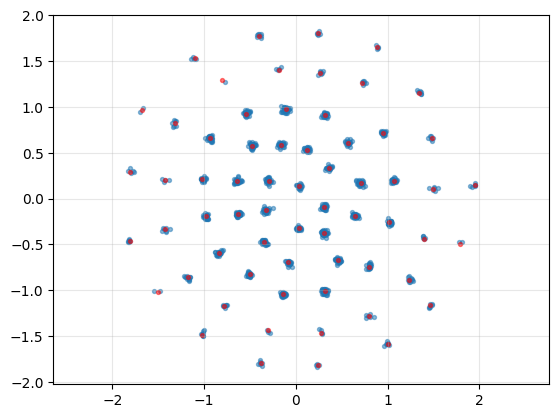

In [190]:
# Example shape: [batch_size, n_symbols]
x_flat = tf.reshape(output_y[:,:500], [-1])

plt.scatter(
    tf.math.real(x_flat).numpy(),
    tf.math.imag(x_flat).numpy(),
    s=8,
    alpha=0.5,
)

x_flat = tf.reshape(norm_const, [-1])

plt.scatter(
    tf.math.real(x_flat).numpy(),
    tf.math.imag(x_flat).numpy(),
    s=8,
    alpha=0.5,
    color='r'
)
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.show()

In [243]:
ber_plot_bicm_short = PlotBER("BER Performance")

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      6.6 | 1.0681e-01 | 1.0000e+00 |      115351 |     1080000 |          100 |         100 |         5.1 |reached target block errors
      6.7 | 1.0416e-01 | 1.0000e+00 |      112498 |     1080000 |          100 |         100 |         5.1 |reached target block errors
      6.8 | 1.0099e-01 | 1.0000e+00 |      109065 |     1080000 |          100 |         100 |         5.7 |reached target block errors
      6.9 | 9.8114e-02 | 1.0000e+00 |      105963 |     1080000 |          100 |         100 |         6.0 |reached target block errors
      7.0 | 9.4450e-02 | 1.0000e+00 |      102006 |     1080000 |          100 |         100 |         5.7 |reached target block errors
      7.1 | 9.0249e-02 | 1.0000e+00 |       97469 |     1080000 |

(<tf.Tensor: shape=(34,), dtype=float32, numpy=
 array([1.0680648e-01, 1.0416482e-01, 1.0098611e-01, 9.8113887e-02,
        9.4449997e-02, 9.0249076e-02, 8.7422222e-02, 8.0744445e-02,
        7.5237960e-02, 6.9210187e-02, 5.8617283e-02, 3.5394032e-02,
        1.5320261e-02, 4.1780863e-03, 1.3064971e-03, 3.0557407e-04,
        3.6277779e-05, 1.5287036e-05, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00], dtype=float32)>,
 <tf.Tensor: shape=(34,), dtype=float32, numpy=
 array([1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
        1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
        1.0000000e+00, 1.0000000e+00, 9.0833336e-01, 6.0000002e-01,
        2.9411766e-01, 8.3333336e-02, 2.8531073e-02, 6.0000001e-03,
        7.9999998e-04, 3.0000001

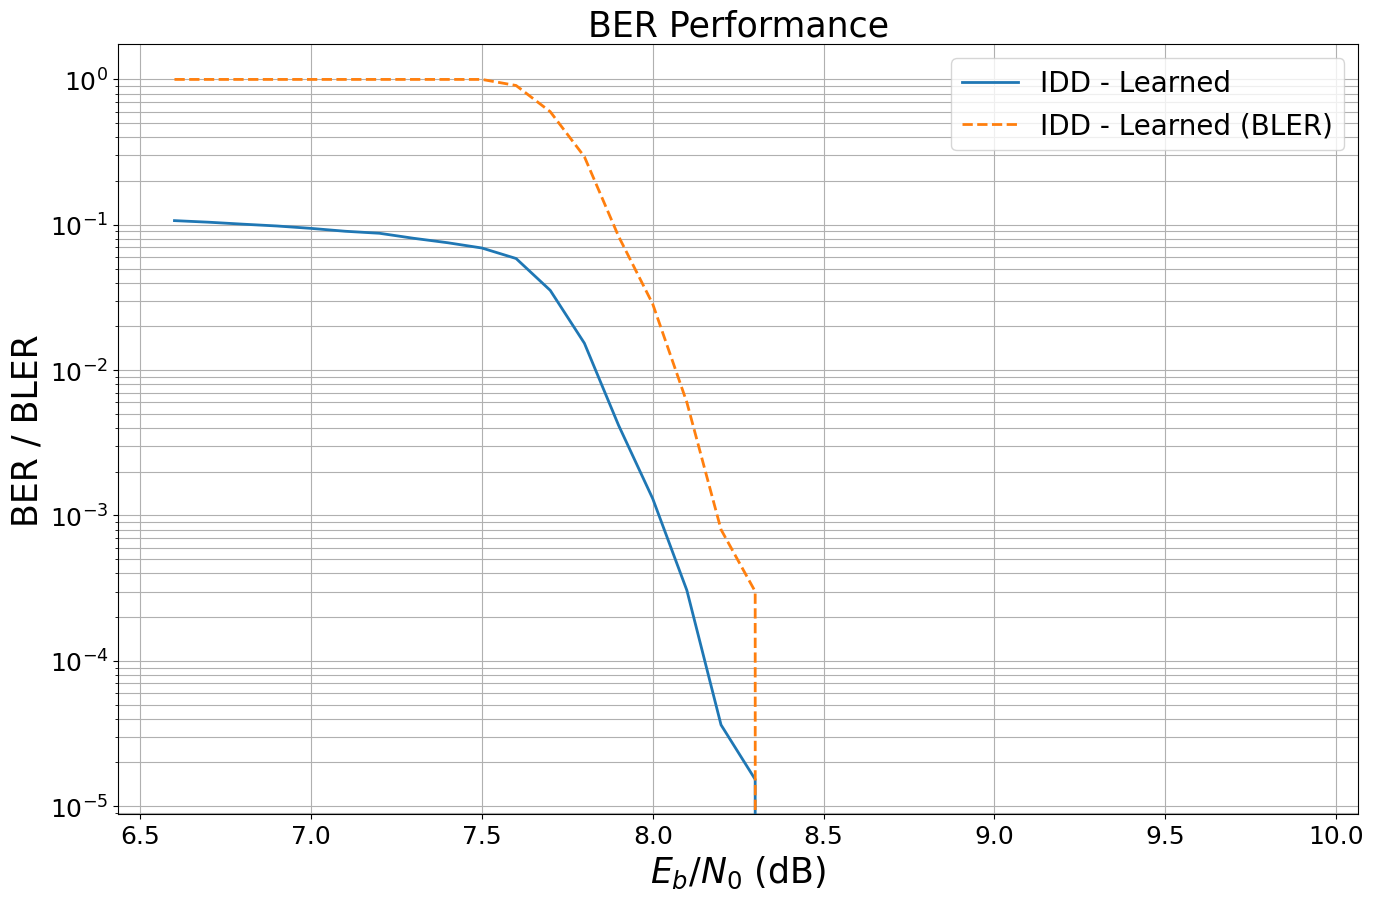

In [244]:


ber_plot_bicm_short.simulate(
    model_idd,
    ebno_dbs=np.arange(6.6, 10.0, 0.1),
    legend="IDD - Learned",
    add_bler=True,
    add_ber=True,
    max_mc_iter=500,
    num_target_block_errors=100,
    batch_size=batch_size,
    soft_estimates=False,
    early_stop=True,
    show_fig=True,
    forward_keyboard_interrupt=False,
)


In [247]:
output_folder = "BLER_results_IDD"
os.makedirs(output_folder, exist_ok=True)

np.savez(
    os.path.join(output_folder, "g1.npz"),
    snr=ber_plot_bicm_short.snr,
    ber=ber_plot_bicm_short.ber
)

In [249]:
ber_plot_bicm_short.ber[1]

<tf.Tensor: shape=(34,), dtype=float32, numpy=
array([1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
       1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
       1.0000000e+00, 1.0000000e+00, 9.0833336e-01, 6.0000002e-01,
       2.9411766e-01, 8.3333336e-02, 2.8531073e-02, 6.0000001e-03,
       7.9999998e-04, 3.0000001e-04, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00], dtype=float32)>

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      5.5 | 4.2002e-02 | 1.0000e+00 |       10887 |      259200 |           24 |          24 |         1.1 |reached target bit errors
      6.0 | 3.0035e-02 | 1.0000e+00 |       10380 |      345600 |           32 |          32 |         0.5 |reached target bit errors
      6.5 | 2.1343e-02 | 1.0000e+00 |       10142 |      475200 |           44 |          44 |         0.7 |reached target bit errors
      7.0 | 1.5115e-02 | 1.0000e+00 |       10121 |      669600 |           62 |          62 |         1.0 |reached target bit errors
      7.5 | 1.1735e-02 | 1.0000e+00 |       10139 |      864000 |           80 |          80 |         1.3 |reached target bit errors
      8.0 | 1.0081e-02 | 1.0000e+00 |       10016 |      993600 |          

(<tf.Tensor: shape=(21,), dtype=float32, numpy=
 array([4.2002317e-02, 3.0034723e-02, 2.1342592e-02, 1.5114994e-02,
        1.1734954e-02, 1.0080515e-02, 8.4200334e-03, 6.1470517e-03,
        4.5442991e-03, 3.0785503e-03, 2.1006945e-03, 1.4377314e-03,
        9.2175923e-04, 5.8703707e-04, 3.7592591e-04, 2.2685186e-04,
        1.2199074e-04, 6.4351851e-05, 4.0972223e-05, 1.7592592e-05,
        1.0416667e-05], dtype=float32)>,
 <tf.Tensor: shape=(21,), dtype=float32, numpy=
 array([1.    , 1.    , 1.    , 1.    , 1.    , 1.    , 1.    , 1.    ,
        1.    , 1.    , 1.    , 0.99  , 0.965 , 0.905 , 0.81  , 0.64  ,
        0.4375, 0.3375, 0.2575, 0.135 , 0.08  ], dtype=float32)>)

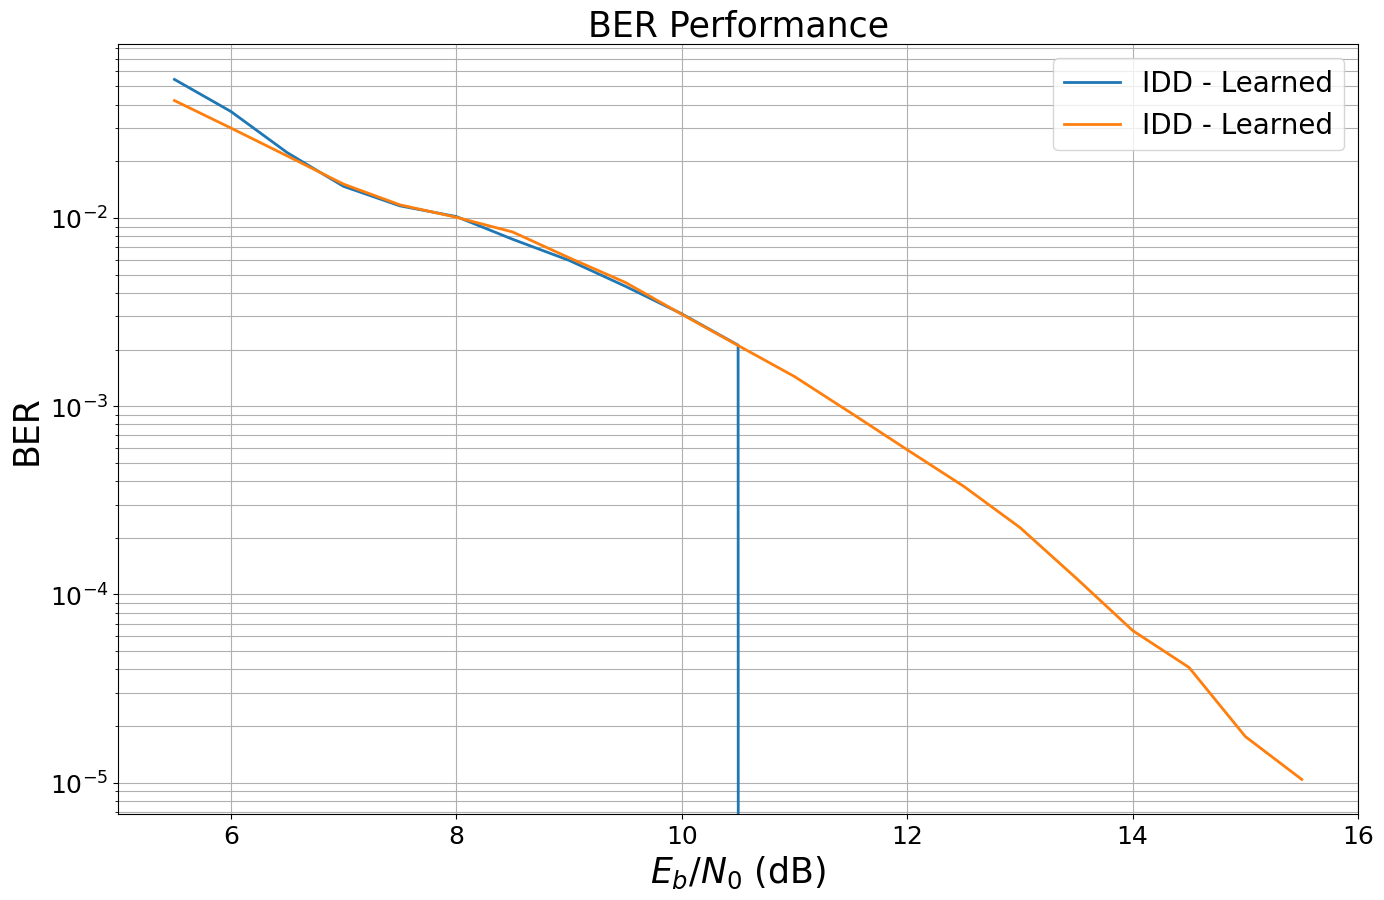

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      7.6 | 1.1896e-02 | 1.0000e+00 |       10278 |      864000 |           80 |          80 |        10.2 |reached target bit errors
     8.24 | 9.9537e-03 | 1.0000e+00 |       10105 |     1015200 |           94 |          94 |        11.8 |reached target bit errors
     8.88 | 7.1346e-03 | 1.0000e+00 |       10017 |     1404000 |          130 |         130 |        16.4 |reached target bit errors
     9.52 | 5.4466e-03 | 1.0000e+00 |       10000 |     1836000 |          170 |         170 |        21.3 |reached target bit errors
    10.16 | 3.3211e-03 | 1.0000e+00 |       10043 |     3024000 |          280 |         280 |        35.0 |reached target bit errors
     10.8 | 2.5918e-03 | 1.0000e+00 |       10021 |     3866400 |          

(<tf.Tensor: shape=(14,), dtype=float32, numpy=
 array([ 1.1895834e-02,  9.9537037e-03,  7.1346154e-03,  5.4466231e-03,
         3.3210979e-03,  2.5918167e-03,  1.5662037e-03,  1.0368056e-03,
         6.3750002e-04,  3.4876543e-04, -1.0000000e+00, -1.0000000e+00,
        -1.0000000e+00, -1.0000000e+00], dtype=float32)>,
 <tf.Tensor: shape=(14,), dtype=float32, numpy=
 array([ 1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
         1.        ,  0.995     ,  0.985     ,  0.935     ,  0.82222223,
        -1.        , -1.        , -1.        , -1.        ], dtype=float32)>)

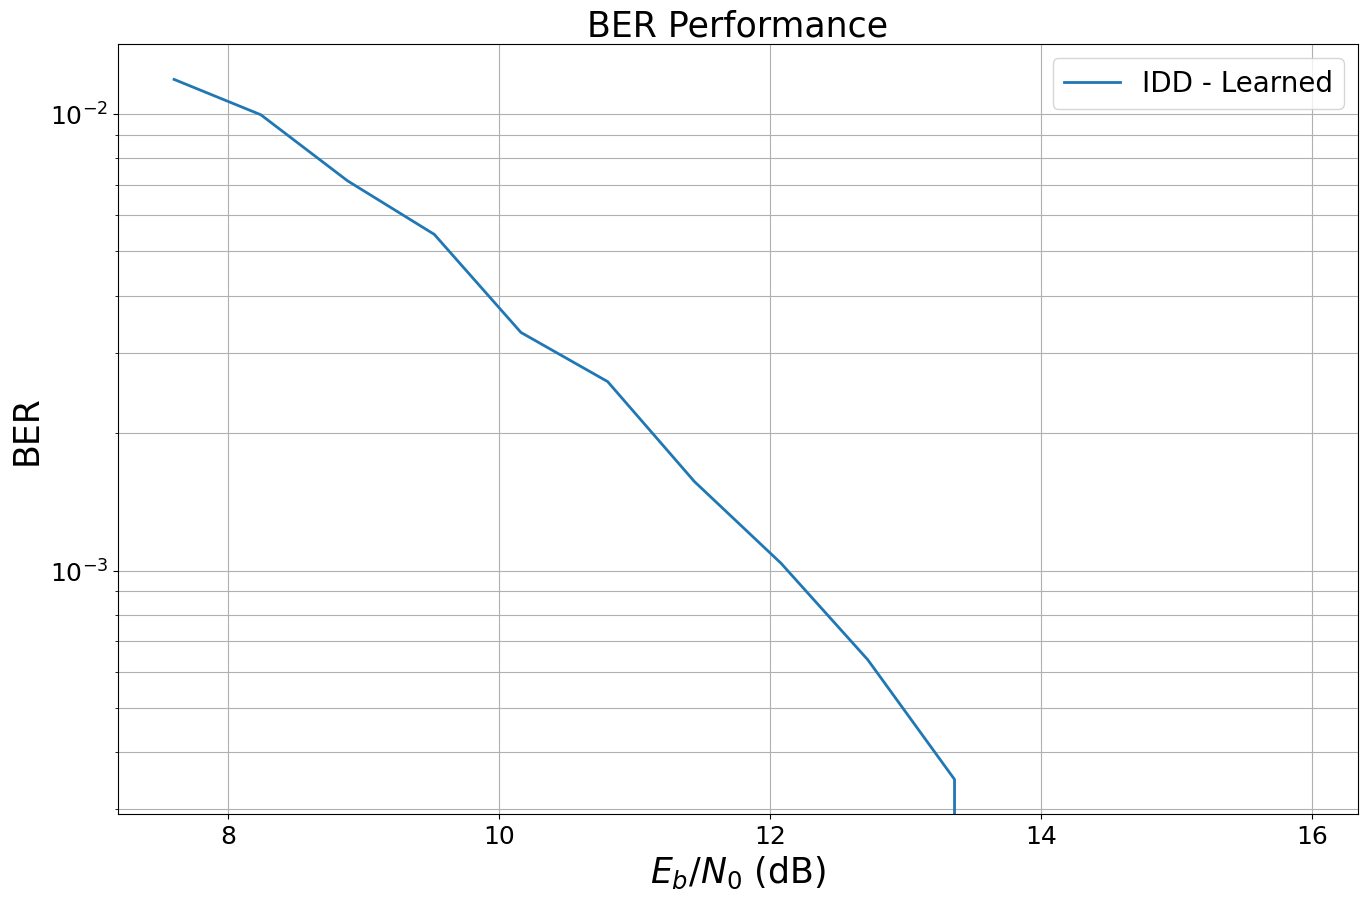

In [38]:
model_idd.L

285

In [40]:
model_idd.ns

10

In [ ]:
2850

In [5]:
def plot_constellation_wlabels(points, probabilities, plot_title):

    points = np.asarray(points)
    probabilities = np.asarray(probabilities).flatten()

    # Scale marker sizes for visibility
    marker_sizes = 300 * probabilities / max(probabilities)

    plt.figure(figsize=(8, 8))
    plt.scatter(points.real, points.imag, s=marker_sizes, alpha=0.7, c='b', edgecolors='k')

    # Annotate with 6-bit binary labels
    for i, pt in enumerate(points):
        label = format(i, '06b')  # 6-bit binary string
        plt.text(pt.real + 0.05, pt.imag + 0.05, label, fontsize=9, ha='left', va='bottom', color='darkred')

    # Add grid and formatting
    plt.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    plt.axvline(0, color='gray', linewidth=0.5, linestyle='--')
    plt.grid(True, linestyle=':')
    plt.xlabel("In-phase")
    plt.ylabel("Quadrature")
    plt.title(plot_title)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.tight_layout()
    # plt.show()

def normalize_constellation(points, probabilities):

    # Compute the power of the constellation
    power = np.sum(probabilities * np.abs(points)**2)
    # Normalize the constellation points
    normalized_points = points / np.sqrt(power)
    return normalized_points

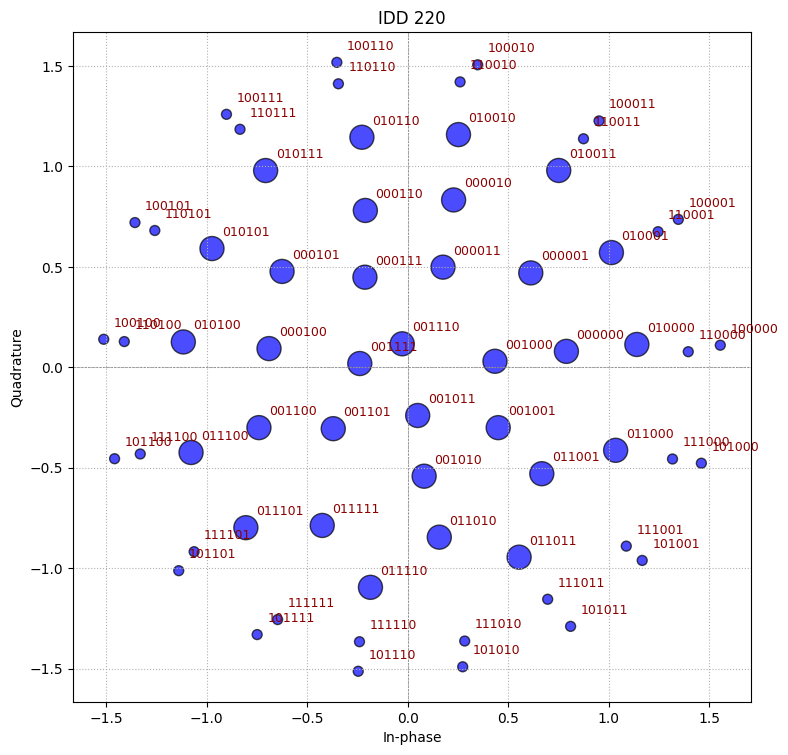

In [229]:
learned_pn_points = normalize_constellation(learned_pn_points, learned_pn_probabilities)

plot_constellation_wlabels(learned_pn_points, learned_pn_probabilities,'IDD 220')

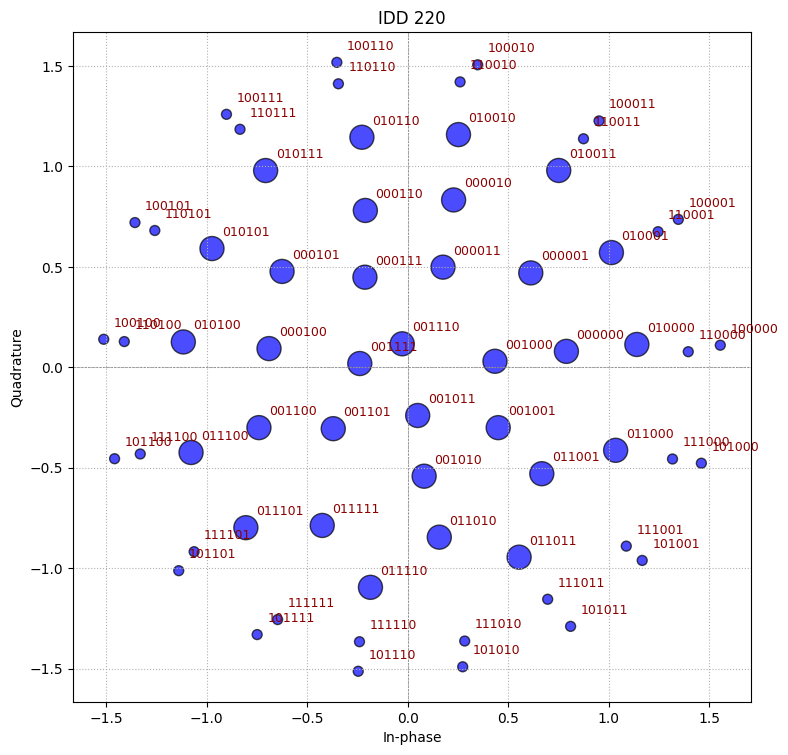

In [264]:
class BICM_IDD_trainable_constellation_g2(Model): # Inherits from Keras Model

    def __init__(self, training, batch_size, num_iter, num_bp_iter, use_dvb, symbol_points, perfect_csi, use_upsampling_filtering_pn, pn_freq, condition):
        super().__init__() # Must call the Keras model initializer

        self.use_dvb = use_dvb
        self.training = training
        self.num_iter = num_iter
        self.batch_size = batch_size

        # init system components
        # source = BinarySource() # generates random info bits
        # we use a simple AWGN channel
        self.channel = AWGN()
        self.num_bits_per_symbol = 6

        ns = 10
        ks = 7
        # weight_counts = {
        #     0: 1,
        #     1: 5,
        #     2: 10
        # }
        cb, _, _, _, p0, _, _ = shaping_encoder_func(ns, ks)
        print('p0 value: ',p0)
        # llr_max_value =  10000.0

        self.ks = ks
        self.ns = ns

        if self.use_dvb:
            llr_max_value = 1000000.0
            r = 2/3
            n_ldpc = 16200
            self.n = n_ldpc
            self.k = int(n_ldpc*r)

            parity_matrix = generate_ldpc_H_matrix(n_ldpc=n_ldpc,rate=r,q=15,file_path="ldpccode_short_2_3.txt")
            H_csr = csr_matrix(parity_matrix[:, :self.k])
            self.H_sparse = tf.sparse.SparseTensor(
                indices=np.vstack((H_csr.nonzero()[0], H_csr.nonzero()[1])).T.astype(np.int64),
                values=H_csr.data.astype(np.int32),
                dense_shape=H_csr.shape
            )
            self.H_sparse_test = csr_matrix(parity_matrix[:, :self.k])

            self.siso_decoder = LDPCBPDecoder(parity_matrix, # connect encoder (for shared code parameters)
                                    cn_update="boxplus-phi", # use the exact boxplus function
                                    num_iter=num_bp_iter,
                                    llr_max=llr_max_value,
                                   hard_out=False,
                                   return_state=True)
            self.source = BinarySource()
        else:
            self.k = 960
            self.n = 1440

            self.binary_source = BinarySource()
            self.encoder = LDPC5GEncoder(self.k, self.n)
            self.siso_decoder = LDPC5GDecoder(self.encoder, return_infobits=False, num_iter=num_bp_iter, hard_out=False, llr_max=llr_max_value, return_state=True)
            self.decoder = LDPC5GDecoder(self.encoder, return_infobits=True, hard_out=True, num_iter=num_bp_iter, llr_max=llr_max_value, return_state=False)


        # Loss function
        self.bce = tf.keras.losses.BinaryCrossentropy(from_logits=True) # Loss function

        # initialize a random interleaver and corresponding deinterleaver
        self.interleaver = RandomInterleaver()
        self.deinterleaver = Deinterleaver(self.interleaver)

        self.interleaver2 = RandomInterleaver()
        self.deinterleaver2 = Deinterleaver(self.interleaver2)


        # self.shapingencoder = Shaping_encoder_neural(ns,ks, batch_size)
        self.shapingencoder = Shaping_encoder(cb,ks)
        # self.p0 = p0

        self.sh_dec_forwrd = Shaping_decoder_forward("app",ks,cb)
        self.sh_dec_backwrd = Shaping_decoder_backward("app",ks,ns,cb)

        constellation = Constellation("custom", num_bits_per_symbol=self.num_bits_per_symbol, points = symbol_points)

        # mapper and demapper
        # self.mapper = Mapper(constellation=constellation)
        self.mapper = Modulator_g2(constellation,p0,self.num_bits_per_symbol)

        if pn_freq == '220':
            fc = 220e9
            pn_var = 0.0108
        elif pn_freq == '120':
            fc = 120e9
            pn_var = 0.0032

        self.demapper = Demapper_optimized("app", constellation=constellation, pn_var=pn_var, condition=condition) # APP demapper

        # self.demapper_nn = Demodulator_bitwise(self.num_bits_per_symbol, batch_size, self.RBF_blocksize)

        ########################
        self.g = 2
        self.L   = math.ceil(self.n / ((self.num_bits_per_symbol - self.g) * ns + self.g*ks ))
        self.num_symbols = int(self.L*self.ns)
        ########################
        # self.prior_values_np = np.zeros((batch_size, self.num_symbols, self.num_bits_per_symbol), dtype=np.float32)

        self.prior_values_np = np.zeros((batch_size, self.L*ns, self.num_bits_per_symbol), dtype=np.float32)

        # self.prior_values_np = np.zeros((batch_size, self.n // self.num_bits_per_symbol, self.num_bits_per_symbol), dtype=np.float32)

        self.prior_values_np[:, :, 0] = np.log((1 - p0) / p0)
        self.prior_values_np[:, :, 5] = np.log((1 - p0) / p0)
        self.llr_d_stream_a_np = np.zeros((batch_size, self.g*self.L*ks), dtype=np.float32)

        self.use_upsampling_filtering_pn  = use_upsampling_filtering_pn

        if use_upsampling_filtering_pn:
            self.upsampler = sn.phy.signal.Upsampling(samples_per_symbol=4)
            self.tx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                             samples_per_symbol=4,
                                                             span_in_symbols=32)
            self.rx_filter = sn.phy.signal.RootRaisedCosineFilter(beta=0.3,
                                                             samples_per_symbol=4,
                                                             span_in_symbols=32)
            num_ptrs_blocks = 36 # Because number of symbols is larger (3645) than 3240 as in uniform BICM case
            symbols_per_ptrs_block = 4
            block_size_ptrs = self.num_symbols+ 4*num_ptrs_blocks
            bandwidth = 960e3*4096
            # fc = 220e9
            samples = 4*(block_size_ptrs+32) #span in symbols

            self.downsampler = sn.phy.signal.Downsampling(samples_per_symbol=4,
                                                          offset = self.rx_filter.length - 1,
                                                     num_symbols=tf.cast(block_size_ptrs, tf.int32))

            path_to_mat = "../PreloadedMats/ptrs_CAZAC_4_64.mat"

            self.ptrs_adder = PTRS_Adder(path_to_mat, num_ptrs_blocks, symbols_per_ptrs_block, block_size_ptrs, batch_size)
            self.pn_compensate = PN_Compensation(self.ptrs_adder.ptrs_indices, self.ptrs_adder.data_indices, block_size_ptrs\
                                                 , self.ptrs_adder.pilots,batch_size, num_ptrs_blocks, symbols_per_ptrs_block)
            self.pn_tx = PhaseNoise(model_type='13', bandwidth=bandwidth, fc=fc, n_samples=samples)
            self.pn_rx = PhaseNoise(model_type='11', bandwidth=bandwidth, fc=fc, n_samples=samples)


    @tf.function # Graph execution to speed things up
    def __call__(self, batch_size, ebno_db):
        # calculate noise variance
        # if self.use_RBF:
        #     no = ebnodb2no(ebno_db,
        #                    num_bits_per_symbol=self.num_bits_per_symbol*(1-1/(self.RBF_blocksize+1)),
        #                    coderate=3/5)
        # else:
        no = ebnodb2no(ebno_db,
           num_bits_per_symbol=3.6,
           coderate=1)

        # p0 = tf.convert_to_tensor(self.p0)
        # p0 = tf.cast(p0,tf.float32)
        prior_values = tf.convert_to_tensor(self.prior_values_np)
        prior_values_flat = tf.reshape(prior_values, [prior_values.shape[0], -1])
        llr_d_stream_a = tf.convert_to_tensor(self.llr_d_stream_a_np)

        if self.use_dvb:
            # b_stream, u_stream = next(self.iterator)
            b_stream = tf.cast(self.source([batch_size, self.k]),tf.int32) # generate random data
            p_bits = tf.transpose(tf.sparse.sparse_dense_matmul(self.H_sparse, tf.transpose(b_stream)))
            p_bits = tf.math.mod(p_bits, 2)
            p_bits = tf.math.mod(tf.math.cumsum(p_bits, axis=1), 2)
            u_stream = tf.concat([b_stream, p_bits], axis=1)
            u_stream = tf.cast(u_stream, tf.uint8)
        else:
            b_stream = self.binary_source([self.batch_size, self.k])
            u_stream = tf.cast(self.encoder(b_stream),tf.uint8)

        ####### zero padding ###########
        # zero_padding = tf.zeros([tf.shape(u_stream)[0], 20], dtype=tf.uint8)
        # u_stream = tf.concat([u_stream, zero_padding], axis=1)
        ################################

        v_stream = self.interleaver(u_stream)
        ##########################################
        # d_stream = v_stream[:, :self.L*self.ks]
        d_stream = v_stream[:, :self.g*self.L*self.ks]

        s1_stream = self.interleaver2(self.shapingencoder(d_stream))
        # s2_stream = v_stream[:, self.L*self.ks:]
        s2_stream = v_stream[:, self.g*self.L*self.ks:]

        # Bit combination operation
        n1 = int(self.L*self.ns)
        # bits = split_dim(s2_stream, [self.num_bits_per_symbol-1, n1], axis=tf.rank(s2_stream)-1)
        bits = split_dim(s2_stream, [self.num_bits_per_symbol-self.g, n1], axis=tf.rank(s2_stream)-1)
        s1_stream_split = split_dim(s1_stream, [self.g,n1], axis = tf.rank(s1_stream)-1)
        result = tf.concat([tf.expand_dims(s1_stream_split[:,0,:], axis=1), bits, tf.expand_dims(s1_stream_split[:,1,:], axis=1)], axis=1)
        # s1_stream_expanded = tf.expand_dims(s1_stream, axis=1)
        # result = tf.concat([s1_stream_expanded, bits], axis=1)
        #############################################
        z_stream = tf.transpose(result, perm=[0, 2, 1])

        # num_symbols = self.n // self.num_bits_per_symbol
        # z_stream = tf.reshape(
        #     v_stream,
        #     [self.batch_size, num_symbols, self.num_bits_per_symbol]
        # )

        x_stream, norm_const_points = self.mapper(z_stream) # map to symbol (APSK)

        if self.use_upsampling_filtering_pn:
            ptrs_x_mod = self.ptrs_adder(x_stream)
            x_up = self.upsampler(ptrs_x_mod)
            x_tx_filt = self.tx_filter(x_up)
            pn_out, _, _ = self.pn_tx(x_tx_filt)
            y_channel = self.channel(pn_out, no)
            y_channel_pn, _, _ = self.pn_rx(y_channel)
            y_rx_filt = self.rx_filter(y_channel_pn)
            y = self.downsampler(y_rx_filt)
            # print('y.shape: ',y.shape)
            _, y_stream = self.pn_compensate(y)
        else:
            y_stream = self.channel(x_stream, no)
            # y_stream = x_stream

        # return y_stream, norm_const_points
        # x_mod_pilots, h_exact = self.pilot_rbf(x_stream, batch_size = self.batch_size)
        # y = self.channel(x_mod_pilots, no) # transmit over AWGN channel
        # y_equalized_stream, h_hat = self.ch_est_equalize(y, no, h_exact)

        ######################################################
        loss_array = tf.TensorArray(dtype=tf.float32, size=self.num_iter)
        msg_v2c = None

        for i_ in range(self.num_iter):

            #########################################################

            llr_z_stream = self.demapper(y_stream, no, norm_const_points, prior_values)


            if self.training:
                z_stream_float = tf.cast(z_stream, tf.float32)
                llr_z_stream_splitdim = split_dim(llr_z_stream, [n1, self.num_bits_per_symbol], axis=tf.rank(llr_z_stream)-1)
                bce_matrix = tf.nn.sigmoid_cross_entropy_with_logits(labels = z_stream_float, logits =llr_z_stream_splitdim)
                loss_val = tf.reduce_sum(tf.reduce_mean(bce_matrix, axis=[0, 1]))
                loss_array = loss_array.write(i_, loss_val)

            llr_z_stream_a = llr_z_stream - prior_values_flat


            llr_z_stream_split = split_dim(llr_z_stream_a, [n1, self.num_bits_per_symbol], axis=tf.rank(llr_z_stream)-1)
            llr_z_stream_split = tf.transpose(llr_z_stream_split, perm=[0, 2, 1])

            # llr_s1_stream = llr_z_stream_split[:, 0, :]
            # llr_s2_stream_split = llr_z_stream_split[:, 1:, :]
            # llr_s2_stream = tf.reshape(llr_s2_stream_split, [self.batch_size, -1])
            ################################
            llr_s1_stream = tf.stack([
                llr_z_stream_split[:, 0, :],
                llr_z_stream_split[:, 5, :]
            ], axis=1)
            llr_s1_stream = tf.reshape(llr_s1_stream, [self.batch_size, -1])

            llr_s2_stream_split = llr_z_stream_split[:, 1:5, :]
            llr_s2_stream = tf.reshape(llr_s2_stream_split, [self.batch_size, -1])
            ################################

            llr_c_stream_a = self.deinterleaver2(llr_s1_stream)

            llr_c_stream_a_split = split_dim(llr_c_stream_a, [self.g*self.L, self.ns], axis=tf.rank(llr_c_stream_a)-1)
            llr_d_stream_a_split = split_dim(llr_d_stream_a, [self.g*self.L, self.ks], axis=tf.rank(llr_d_stream_a)-1)
            llr_d_stream = self.sh_dec_forwrd(llr_c_stream_a_split, llr_d_stream_a_split)

            llr_v_stream = tf.concat([llr_d_stream,llr_s2_stream], axis=1)
            llr_u_stream_a = self.deinterleaver(llr_v_stream)


            [llr_u_stream, msg_v2c] = self.siso_decoder(llr_u_stream_a, msg_v2c=msg_v2c) # run LDPC decoder
            llr_u_stream_e = llr_u_stream - llr_u_stream_a

            ####### Negative LLR padding ###########
            # llr_padding = -tf.ones([tf.shape(llr_u_stream_e)[0], 20], dtype=tf.float32)*50
            # llr_u_stream_e = tf.concat([llr_u_stream_e, llr_padding], axis=1)
            ################################

            llr_v_stream_a = self.interleaver(llr_u_stream_e)
            ################################################################
            # llr_d_stream_a = llr_v_stream_a[:, :self.L*self.ks]
            # llr_s2_stream_a = llr_v_stream_a[:, self.L*self.ks:]
            llr_d_stream_a = llr_v_stream_a[:, :self.g*self.L*self.ks]
            llr_s2_stream_a = llr_v_stream_a[:, self.g*self.L*self.ks:]

            # llr_c_stream_a_split = split_dim(llr_c_stream_a, [self.L, self.ns], axis=tf.rank(llr_c_stream_a)-1)
            # llr_d_stream_a_split = split_dim(llr_d_stream_a, [self.L, self.ks], axis=tf.rank(llr_d_stream_a)-1)
            llr_c_stream_a_split = split_dim(llr_c_stream_a, [self.g*self.L, self.ns], axis=tf.rank(llr_c_stream_a)-1)
            llr_d_stream_a_split = split_dim(llr_d_stream_a, [self.g*self.L, self.ks], axis=tf.rank(llr_d_stream_a)-1)

            llr_c_stream =  self.sh_dec_backwrd(llr_c_stream_a_split, llr_d_stream_a_split)
            llr_s1_stream_a = self.interleaver2(llr_c_stream)

            # Bit combination operation
            # bits_rev = split_dim(llr_s2_stream_a, [self.num_bits_per_symbol-1, n1], axis=tf.rank(llr_s2_stream_a)-1)
            # llr_s1_stream_a_expanded = tf.expand_dims(llr_s1_stream_a, axis=1)
            # result_rev = tf.concat([llr_s1_stream_a_expanded, bits_rev], axis=1)
            # prior_values = tf.transpose(result_rev, perm=[0, 2, 1])
            #
            # prior_values_flat = tf.reshape(prior_values, [self.batch_size, -1])

            # Bit combination operation
            bits_rev = split_dim(llr_s2_stream_a, [self.num_bits_per_symbol-self.g, n1], axis=tf.rank(llr_s2_stream_a)-1)
            llr_s1_stream_a_split = split_dim(llr_s1_stream_a, [self.g,n1], axis=tf.rank(llr_s1_stream_a)-1)

            result_rev = tf.concat([tf.expand_dims(llr_s1_stream_a_split[:,0,:], axis=1), bits_rev, tf.expand_dims(llr_s1_stream_a_split[:,1,:], axis=1)], axis=1)
            prior_values = tf.transpose(result_rev, perm=[0, 2, 1])

            prior_values_flat = tf.reshape(prior_values, [self.batch_size, -1])

            # print(prior_values_flat[0,:20])

            if i_ == self.num_iter - 1:
                del llr_u_stream_e, llr_z_stream, llr_v_stream_a, llr_s2_stream, llr_s1_stream, llr_z_stream_a, \
                    llr_z_stream_split, llr_s2_stream_split, llr_c_stream_a, llr_c_stream_a_split, \
                    llr_d_stream, llr_v_stream, llr_c_stream, llr_s1_stream_a, \
                    llr_s2_stream_a, bits_rev, result_rev, prior_values, prior_values_flat, \
                    llr_d_stream_a_split
            else:
                del llr_u_stream_e, llr_z_stream, llr_u_stream_a, llr_v_stream_a, llr_u_stream, \
                    llr_s2_stream, llr_s1_stream, llr_z_stream_a, llr_z_stream_split, llr_s2_stream_split, \
                    llr_c_stream_a, llr_c_stream_a_split, llr_d_stream, llr_v_stream, llr_c_stream, \
                    llr_s1_stream_a, llr_s2_stream_a, bits_rev, result_rev, \
                    llr_d_stream_a_split
                if self.training:
                    del llr_z_stream_splitdim, bce_matrix


        if self.training:

            loss_array_stacked = loss_array.stack()
            return tf.reduce_mean(loss_array_stacked), loss_array_stacked

        else:

            if self.use_dvb:
                u_stream_hat = tf.cast(tf.greater_equal(0.0, -llr_u_stream), tf.int32)
                b_stream_hat = u_stream_hat[:,:self.k]
                return b_stream, b_stream_hat
            else:
                b_stream_hat = self.decoder(llr_u_stream_a, msg_v2c=msg_v2c) # run LDPC decoder
                return b_stream, b_stream_hat

In [3]:
learned_pn_points_g2 = np.load(f"constellations_for_plot2_7_0_papr/220_papr_7_0_g2.npz")['constellation_points']
learned_pn_probabilities_g2 = np.load(f"constellations_for_plot2_7_0_papr/220_papr_7_0_g2.npz")['constellation_probabilities']

In [270]:
batch_size = 20
num_bp_iter = 40
use_dvb = True
perfect_csi = False
use_upsampling_filtering_pn = True
num_iter = 10
pn_freq = '220'
condition = 'lowpn' # awgn highsnr

model_idd = BICM_IDD_trainable_constellation_g2(False, batch_size, num_iter, num_bp_iter, use_dvb, learned_pn_points_g2, perfect_csi, use_upsampling_filtering_pn, pn_freq, condition)



p0 value:  0.753125


In [271]:
output_y, norm_const = model_idd(tf.constant(batch_size, tf.int32), tf.constant(26.0, tf.float32))

In [273]:
ber_plot_bicm = PlotBER("BER Performance")

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
      6.6 | 1.3710e-01 | 1.0000e+00 |      148073 |     1080000 |          100 |         100 |         6.4 |reached target block errors
      6.7 | 1.3511e-01 | 1.0000e+00 |      145916 |     1080000 |          100 |         100 |         6.2 |reached target block errors
      6.8 | 1.3143e-01 | 1.0000e+00 |      141942 |     1080000 |          100 |         100 |         6.2 |reached target block errors
      6.9 | 1.2849e-01 | 1.0000e+00 |      138771 |     1080000 |          100 |         100 |         6.2 |reached target block errors
      7.0 | 1.2589e-01 | 1.0000e+00 |      135964 |     1080000 |          100 |         100 |         6.2 |reached target block errors
      7.1 | 1.2337e-01 | 1.0000e+00 |      133244 |     1080000 |

(<tf.Tensor: shape=(34,), dtype=float32, numpy=
 array([1.37104630e-01, 1.35107413e-01, 1.31427780e-01, 1.28491670e-01,
        1.25892594e-01, 1.23374075e-01, 1.19372219e-01, 1.16932407e-01,
        1.12705559e-01, 1.09635182e-01, 1.05634257e-01, 1.00210182e-01,
        9.50439796e-02, 8.75478387e-02, 6.87345713e-02, 4.33009267e-02,
        1.94475316e-02, 6.12464407e-03, 1.62009394e-03, 2.07305551e-04,
        5.38518507e-05, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00], dtype=float32)>,
 <tf.Tensor: shape=(34,), dtype=float32, numpy=
 array([1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
        1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
        1.0000000e+00, 1.0000000e+00, 1.0000000e+00, 1.0000000e+00,
        9.8333335e-01, 9.7500002e-01, 8.4166664e-01, 5.8888888e-01

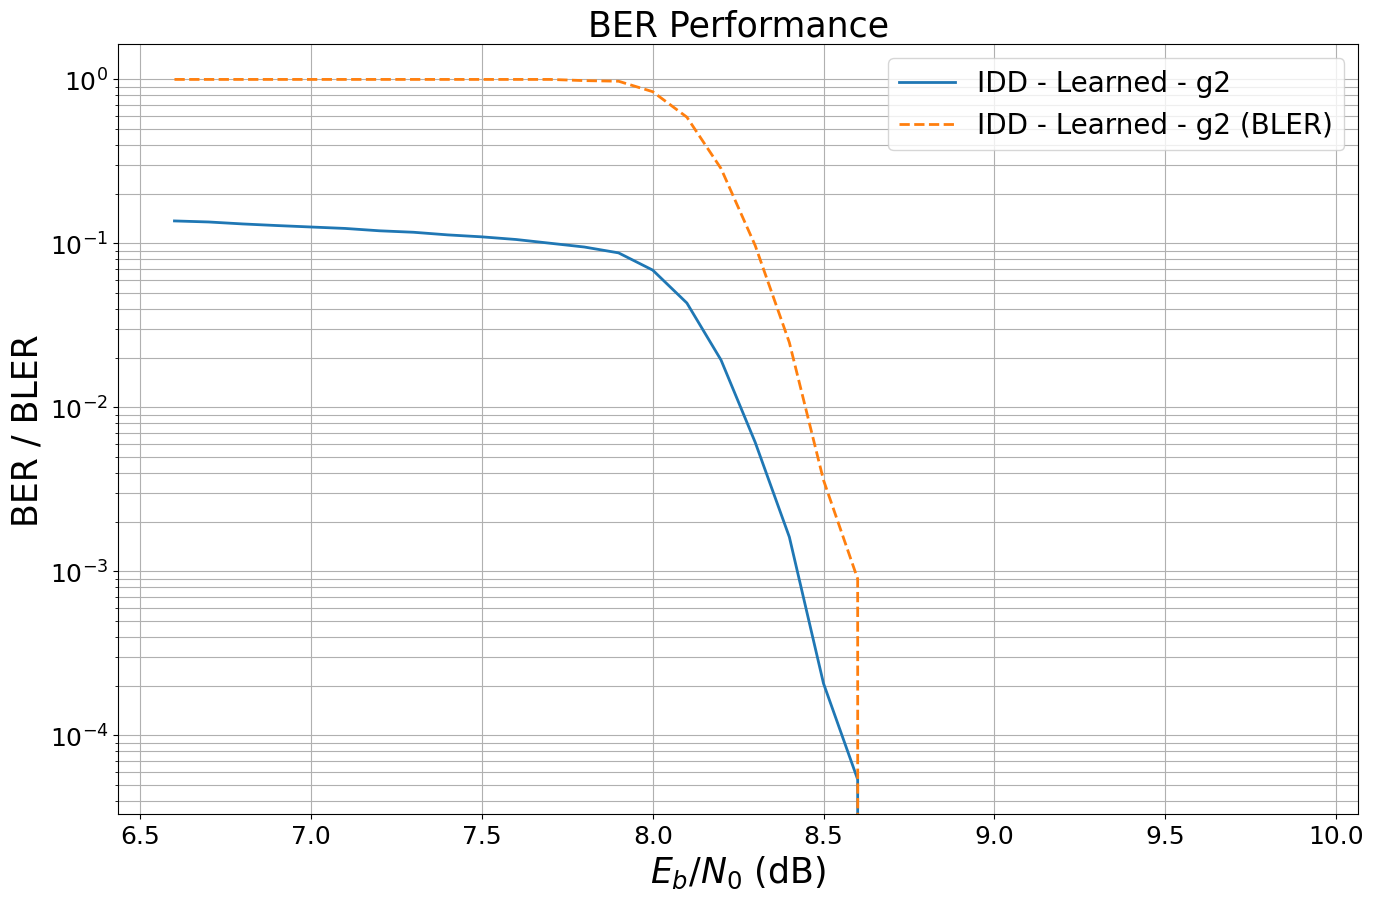

In [274]:

ber_plot_bicm.simulate(
    model_idd,
    ebno_dbs=np.arange(6.6, 10.0, 0.1),
    legend="IDD - Learned - g2",
    add_bler=True,
    add_ber=True,
    max_mc_iter=500,
    num_target_block_errors=100,
    batch_size=batch_size,
    soft_estimates=False,
    early_stop=True,
    show_fig=True,
    forward_keyboard_interrupt=False,
)


In [275]:
output_folder = "BLER_results_IDD"
os.makedirs(output_folder, exist_ok=True)

np.savez(
    os.path.join(output_folder, "g2.npz"),
    snr=ber_plot_bicm.snr,
    ber=ber_plot_bicm.ber
)

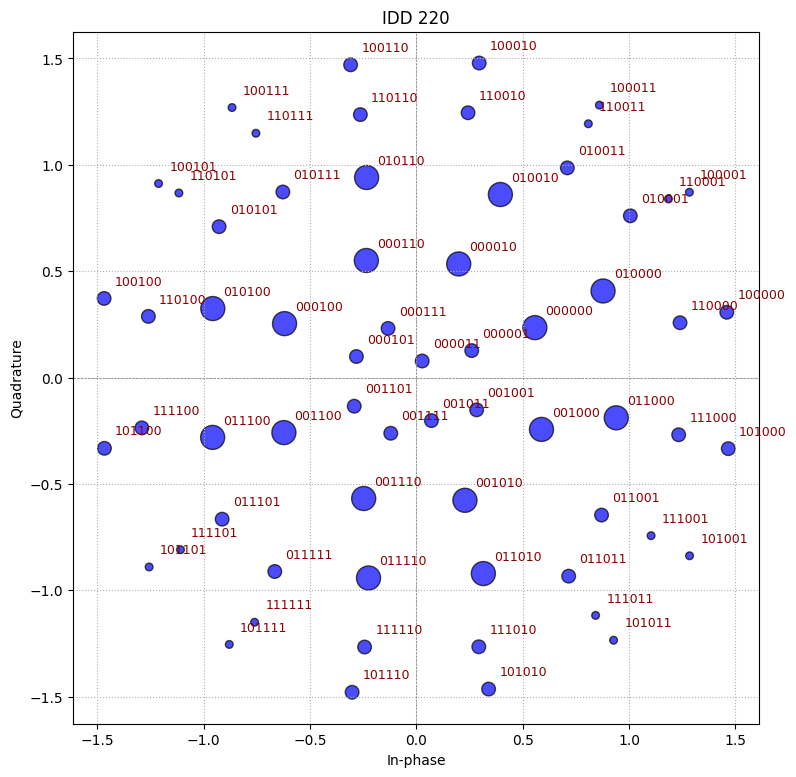

In [7]:
learned_pn_points_g2 = normalize_constellation(learned_pn_points_g2, learned_pn_probabilities_g2)

plot_constellation_wlabels(learned_pn_points_g2, learned_pn_probabilities_g2,'IDD 220')